# Assignment 3B – Diabetes Dataset: Univariate, Bivariate & Multiple Regression Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import classification_report, r2_score, mean_squared_error

## 1. Load Datasets

In [2]:
cdc  = pd.read_csv('cdc_diabetes.csv')
pima = pd.read_csv('Pima_Diabetes.csv')

print('CDC shape :', cdc.shape)
print('Pima shape:', pima.shape)

CDC shape : (70692, 22)
Pima shape: (768, 9)


## 2. Univariate Analysis

In [3]:
def univariate_stats(df, name):
    stats_df = df.describe().T
    stats_df['skewness'] = df.skew()
    stats_df['kurtosis'] = df.kurtosis()
    stats_df['median']   = df.median()
    stats_df['mode']     = df.mode().iloc[0]
    print(f'\n=== {name} Univariate Stats ===')
    return stats_df[['mean','median','mode','std','min','max','skewness','kurtosis']]

display(univariate_stats(cdc,  'CDC Diabetes'))
display(univariate_stats(pima, 'Pima Diabetes'))


=== CDC Diabetes Univariate Stats ===


,mean,median,mode,std,min,max,skewness,kurtosis
Diabetes_binary,0.500000,0.5,0.0,0.500004,0.0,1.0,0.000000,-2.000057
HighBP,0.563458,1.0,1.0,0.495960,0.0,1.0,-0.255908,-1.934566
HighChol,0.525703,1.0,1.0,0.499342,0.0,1.0,-0.102950,-1.989457
CholCheck,0.975259,1.0,1.0,0.155336,0.0,1.0,-6.119271,35.446486
BMI,29.856985,29.0,27.0,7.113954,12.0,98.0,1.719180,7.164081
Smoker,0.475273,0.0,0.0,0.499392,0.0,1.0,0.099031,-1.990249
Stroke,0.062171,0.0,0.0,0.241468,0.0,1.0,3.626499,11.151808
HeartDiseaseorAttack,0.147810,0.0,0.0,0.354914,0.0,1.0,1.984703,1.939102
PhysActivity,0.703036,1.0,1.0,0.456924,0.0,1.0,-0.888732,-1.210190
Fruits,0.611795,1.0,1.0,0.487345,0.0,1.0,-0.458804,-1.789549



=== Pima Diabetes Univariate Stats ===


,mean,median,mode,std,min,max,skewness,kurtosis
Pregnancies,3.845052,3.0000,1.000,3.369578,0.000,17.00,0.901674,0.159220
Glucose,120.894531,117.0000,99.000,31.972618,0.000,199.00,0.173754,0.640780
BloodPressure,69.105469,72.0000,70.000,19.355807,0.000,122.00,-1.843608,5.180157
SkinThickness,20.536458,23.0000,0.000,15.952218,0.000,99.00,0.109372,-0.520072
Insulin,79.799479,30.5000,0.000,115.244002,0.000,846.00,2.272251,7.214260
BMI,31.992578,32.0000,32.000,7.884160,0.000,67.10,-0.428982,3.290443
DiabetesPedigreeFunction,0.471876,0.3725,0.254,0.331329,0.078,2.42,1.919911,5.594954
Age,33.240885,29.0000,22.000,11.760232,21.000,81.00,1.129597,0.643159
Outcome,0.348958,0.0000,0.000,0.476951,0.000,1.00,0.635017,-1.600930


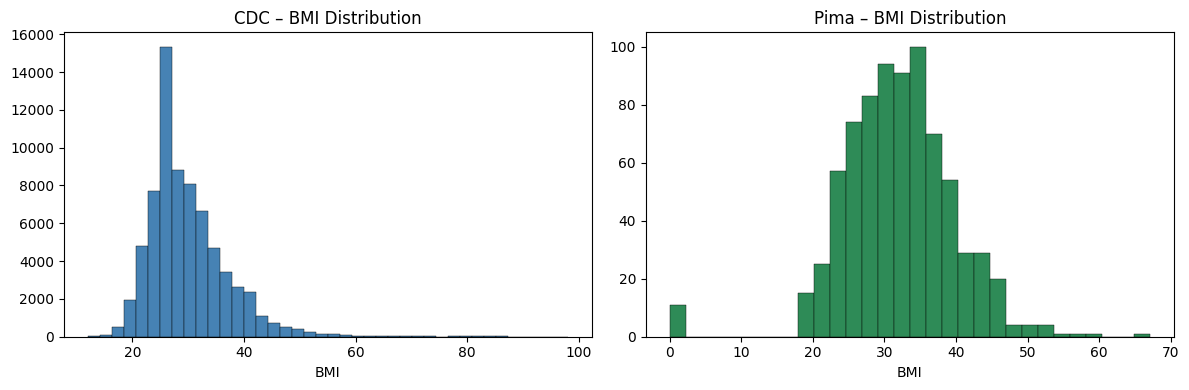

In [4]:
# Histogram of BMI in both datasets
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cdc['BMI'], bins=40, color='steelblue', edgecolor='k', linewidth=0.3)
axes[0].set_title('CDC – BMI Distribution')
axes[0].set_xlabel('BMI')

axes[1].hist(pima['BMI'], bins=30, color='seagreen', edgecolor='k', linewidth=0.3)
axes[1].set_title('Pima – BMI Distribution')
axes[1].set_xlabel('BMI')

plt.tight_layout()
plt.show()

## 3. Bivariate Analysis – Linear Regression (BMI → Blood Pressure / Glucose)

Pima BMI vs Glucose: r=0.221, p=0.0000


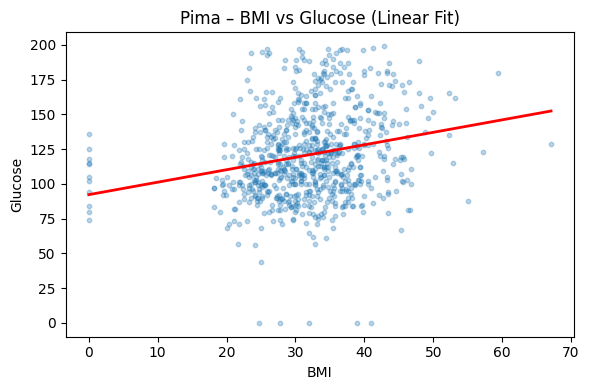

In [5]:
# Pima: BMI vs Glucose scatter + linear fit
slope, intercept, r_value, p_value, _ = stats.linregress(pima['BMI'], pima['Glucose'])
print(f'Pima BMI vs Glucose: r={r_value:.3f}, p={p_value:.4f}')

plt.figure(figsize=(6, 4))
plt.scatter(pima['BMI'], pima['Glucose'], alpha=0.3, s=10)
x_line = np.linspace(pima['BMI'].min(), pima['BMI'].max(), 100)
plt.plot(x_line, slope*x_line + intercept, 'r-', linewidth=2)
plt.xlabel('BMI')
plt.ylabel('Glucose')
plt.title('Pima – BMI vs Glucose (Linear Fit)')
plt.tight_layout()
plt.show()

In [6]:
# Logistic regression: predict diabetes outcome (Pima)
pima_clean = pima[(pima[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] != 0).all(axis=1)]

X_p = pima_clean.drop('Outcome', axis=1)
y_p = pima_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X_p, y_p, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

lr = LogisticRegression(max_iter=500)
lr.fit(X_train_s, y_train)
print('=== Pima – Logistic Regression ===')
print(classification_report(y_test, lr.predict(X_test_s)))

=== Pima – Logistic Regression ===
              precision    recall  f1-score   support

           0       0.80      0.87      0.83        52
           1       0.70      0.59      0.64        27

    accuracy                           0.77        79
   macro avg       0.75      0.73      0.74        79
weighted avg       0.77      0.77      0.77        79



## 4. Multiple Regression – CDC Dataset

In [7]:
# Sample CDC (large dataset) for speed
cdc_s = cdc.sample(10000, random_state=42)

X_c = cdc_s.drop('Diabetes_binary', axis=1)
y_c = cdc_s['Diabetes_binary']

X_train, X_test, y_train, y_test = train_test_split(X_c, y_c, test_size=0.2, random_state=42)
scaler_c = StandardScaler()
X_train_sc = scaler_c.fit_transform(X_train)
X_test_sc  = scaler_c.transform(X_test)

lr_cdc = LogisticRegression(max_iter=500)
lr_cdc.fit(X_train_sc, y_train)
print('=== CDC – Logistic Regression ===')
print(classification_report(y_test, lr_cdc.predict(X_test_sc)))

=== CDC – Logistic Regression ===
              precision    recall  f1-score   support

         0.0       0.77      0.74      0.76      1035
         1.0       0.73      0.76      0.75       965

    accuracy                           0.75      2000
   macro avg       0.75      0.75      0.75      2000
weighted avg       0.75      0.75      0.75      2000



## 5. Compare Key Statistics – CDC vs Pima

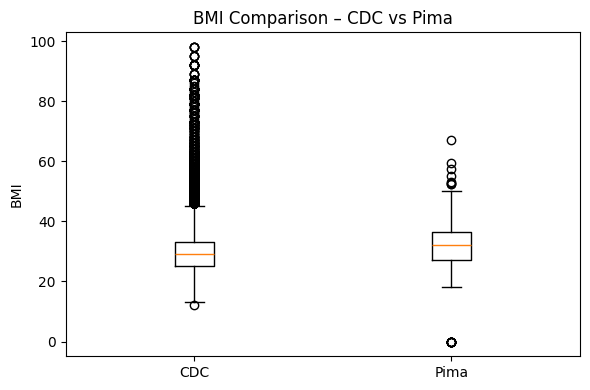

CDC  – Diabetes prevalence: 0.5
Pima – Diabetes prevalence: 0.3489583333333333


In [10]:
common_cols = ['BMI']

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([cdc['BMI'], pima['BMI']], tick_labels=['CDC', 'Pima'])
ax.set_title('BMI Comparison – CDC vs Pima')
ax.set_ylabel('BMI')
plt.tight_layout()
plt.show()

print('CDC  – Diabetes prevalence:', cdc['Diabetes_binary'].mean())
print('Pima – Diabetes prevalence:', pima['Outcome'].mean())

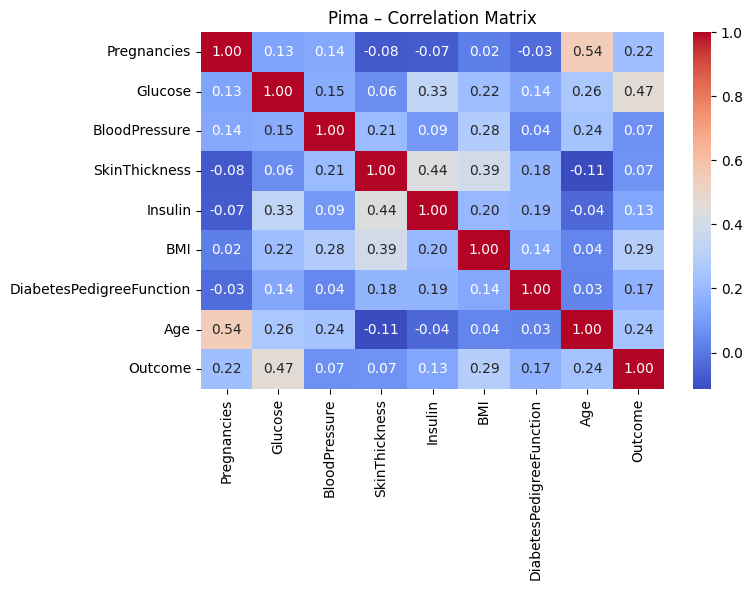

In [9]:
# Correlation heatmap – Pima
plt.figure(figsize=(8, 6))
sns.heatmap(pima.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Pima – Correlation Matrix')
plt.tight_layout()
plt.show()